# 05 Map: electricity tariffs 2026 by municipality

Bonus: geodata. Municipality boundaries 2026 (generalised) from the npm package *swiss-maps* 4.7.0, source: Bundesamt für Statistik (BFS), GEOSTAT. Joined to our tariffs on the BFS municipality number (2,108 of 2,113 areas have a tariff). Tariffs: H4 2026, Rp./kWh excl. VAT.

Gemeinden auf der Karte: 2113
davon ohne Tarif: 5


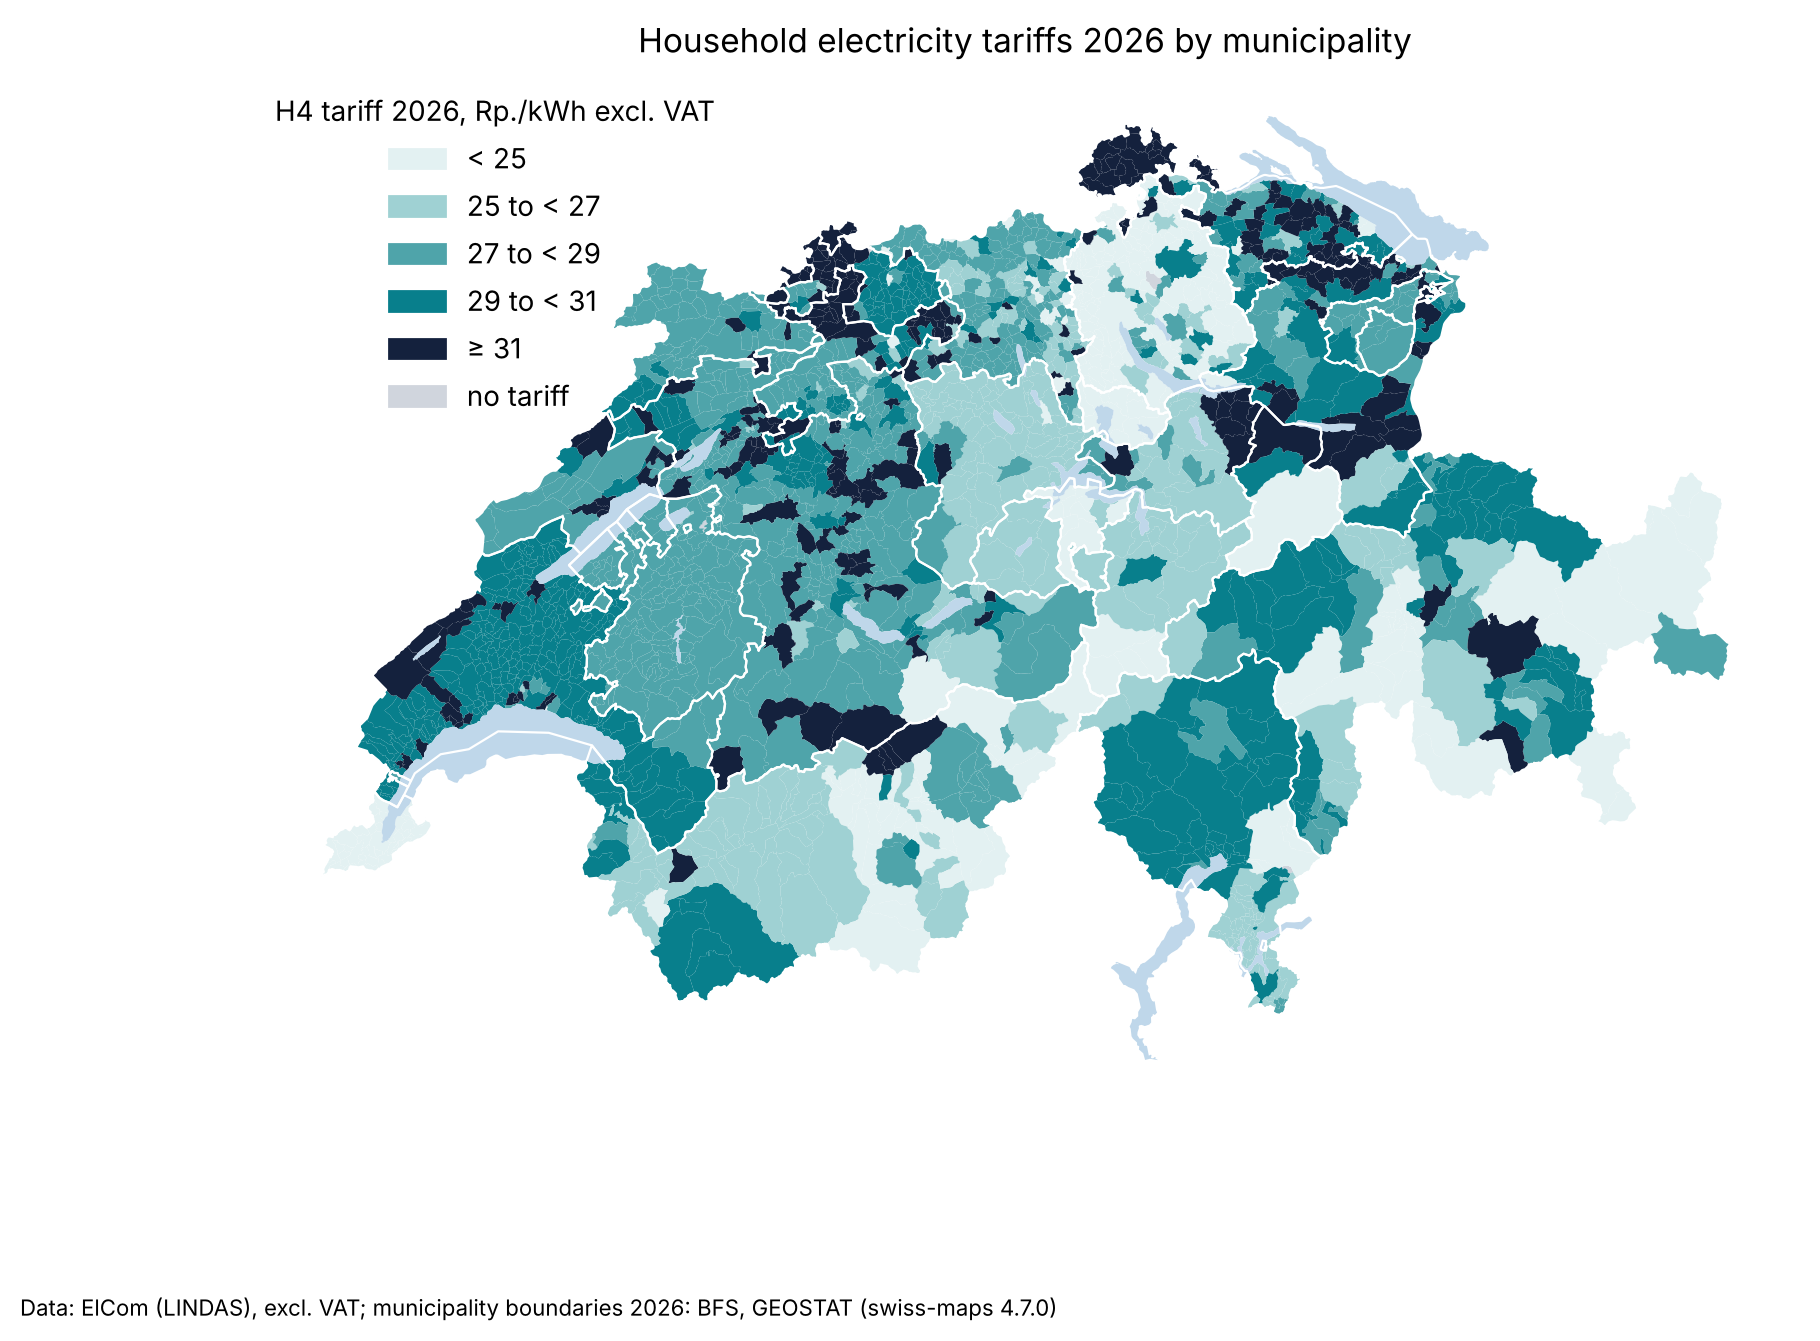

In [1]:
# Karte: Stromtarife 2026 pro Gemeinde (Bonus Geodaten)
# Gemeindegrenzen: Paket "swiss-maps" (npm), Quelle: Bundesamt für Statistik (BFS), GEOSTAT
# Voraussetzung: pip install geopandas matplotlib

import io
import tarfile
import urllib.request
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

ROOT = Path("..")                      # Notebook liegt im Ordner maps/
GEO_DIR = ROOT / "maps" / "geodata"     # wird automatisch heruntergeladen, nicht committen
OUT = ROOT / "maps" / "map_tariffs_2026.png"

# 1) Gemeindegrenzen 2026 einmalig herunterladen und entpacken
if not (GEO_DIR / "package" / "2026" / "municipalities.shp").exists():
    url = "https://registry.npmjs.org/swiss-maps/-/swiss-maps-4.7.0.tgz"
    data = urllib.request.urlopen(url).read()
    GEO_DIR.mkdir(parents=True, exist_ok=True)
    with tarfile.open(fileobj=io.BytesIO(data)) as tar:
        members = [m for m in tar.getmembers() if m.name.startswith("package/2026/")]
        tar.extractall(GEO_DIR, members=members)

shp = GEO_DIR / "package" / "2026"
gemeinden = gpd.read_file(shp / "municipalities.shp")   # Spalte "id" = BFS-Gemeindenummer
kantone = gpd.read_file(shp / "cantons.shp")
seen = gpd.read_file(shp / "lakes.shp")

# 2) Unsere Tarife pro Gemeinde dazuholen (Schlüssel: BFS-Gemeindenummer)
tarife = pd.read_csv(ROOT / "data" / "processed" / "municipality_values.csv")
karte = gemeinden.merge(
    tarife[["municipality_number_2026", "municipality_tariff"]],
    left_on="id", right_on="municipality_number_2026", how="left",
)
print("Gemeinden auf der Karte:", len(karte))
print("davon ohne Tarif:", karte["municipality_tariff"].isna().sum())

# 3) Zeichnen: 5 Klassen in Rp./kWh
grenzen = [0, 25, 27, 29, 31, 100]
farben = ["#E3F1F2", "#9FD1D3", "#4FA4AA", "#087F8C", "#14213D"]
labels = ["< 25", "25 to < 27", "27 to < 29", "29 to < 31", "≥ 31"]
cmap = ListedColormap(farben)
norm = BoundaryNorm(grenzen, cmap.N)

fig, ax = plt.subplots(figsize=(10, 7.5))
karte[karte["municipality_tariff"].isna()].plot(ax=ax, color="#D0D5DD", linewidth=0)
karte.dropna(subset=["municipality_tariff"]).plot(
    ax=ax, column="municipality_tariff", cmap=cmap, norm=norm, linewidth=0)
seen.plot(ax=ax, color="#BFD7EA", linewidth=0)
kantone.boundary.plot(ax=ax, color="white", linewidth=0.8)

legende = [Patch(color=c, label=l) for c, l in zip(farben, labels)]
legende.append(Patch(color="#D0D5DD", label="no tariff"))
ax.legend(handles=legende, title="H4 tariff 2026, Rp./kWh excl. VAT", loc="upper left", frameon=False)
ax.set_axis_off()
ax.set_title("Household electricity tariffs 2026 by municipality")
fig.text(0.01, 0.01, "Data: ElCom (LINDAS), excl. VAT; municipality boundaries 2026: BFS, GEOSTAT (swiss-maps 4.7.0)", fontsize=8)

OUT.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT, dpi=200, bbox_inches="tight", transparent=True)
plt.show()
